
# 03. ResNet18 Baseline Model

## Objective
Establish a baseline for fetal ultrasound anatomical plane classification using ResNet18.

## Methodology
1. Load the saved patient-level train, validation and test splits.
2. Initialize an ImageNet-pretrained ResNet18.
3. Replace the final classification layer with a six-class output layer.
4. Train the model using CrossEntropyLoss and Adam.
5. Evaluate on the validation set.
6. Save the best model checkpoint and training history.

The original test set will remain untouched until final evaluation.


In [1]:

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 0.0001

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "Images"
SPLIT_DIR = DATA_DIR / "splits"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)


Device: cpu
Epochs: 3
Batch size: 16


In [2]:

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

for frame in [train_df, val_df, test_df]:
    frame["image_path"] = frame["Image_name"].apply(
        lambda name: IMAGE_DIR / f"{name}.png"
    )

classes = sorted(train_df["Plane"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

print("Classes:", class_to_idx)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Classes: {'Fetal abdomen': 0, 'Fetal brain': 1, 'Fetal femur': 2, 'Fetal thorax': 3, 'Maternal cervix': 4, 'Other': 5}
Training: 6217
Validation: 912
Testing: 5271


In [3]:

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])


class FetalDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        label = class_to_idx[row["Plane"]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = FetalDataset(train_df, train_transform)
val_dataset = FetalDataset(val_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 389
Validation batches: 57


In [4]:

weights = ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(classes))

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print(model.fc)
print("\nResNet18 initialized successfully!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\HP/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Linear(in_features=512, out_features=6, bias=True)

ResNet18 initialized successfully!


In [5]:

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    model.train()
    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_predictions.extend(predictions.tolist())
        train_targets.extend(labels.tolist())

    train_loss = running_loss / len(train_dataset)
    train_acc = accuracy_score(
        train_targets, train_predictions
    )

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_predictions.extend(predictions.tolist())
            val_targets.extend(labels.tolist())

    val_loss = val_running_loss / len(val_dataset)
    val_acc = accuracy_score(val_targets, val_predictions)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_model_weights,
            "classes": classes,
            "class_to_idx": class_to_idx,
            "epoch": epoch + 1,
            "val_accuracy": val_acc
        }, MODEL_DIR / "resnet18_baseline_best.pth")

    elapsed = time.time() - start_time

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Time: {elapsed/60:.2f} minutes")

print("\nBaseline training completed!")
print("Best validation accuracy:", best_val_accuracy)



Epoch 1/3
Train Loss: 0.3027
Train Accuracy: 0.9000
Validation Loss: 0.2298
Validation Accuracy: 0.9342
Time: 19.59 minutes

Epoch 2/3
Train Loss: 0.1664
Train Accuracy: 0.9468
Validation Loss: 0.2287
Validation Accuracy: 0.9254
Time: 16.60 minutes

Epoch 3/3
Train Loss: 0.1207
Train Accuracy: 0.9595
Validation Loss: 0.1814
Validation Accuracy: 0.9441
Time: 15.96 minutes

Baseline training completed!
Best validation accuracy: 0.944078947368421


In [6]:

history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULTS_DIR / "baseline_training_history.csv",
    index=False
)

print("Training history saved!")
display(history_df)


Training history saved!


,train_loss,val_loss,train_accuracy,val_accuracy
0,0.302674,0.229847,0.899952,0.934211
1,0.166436,0.228663,0.946759,0.925439
2,0.120653,0.181399,0.959466,0.944079


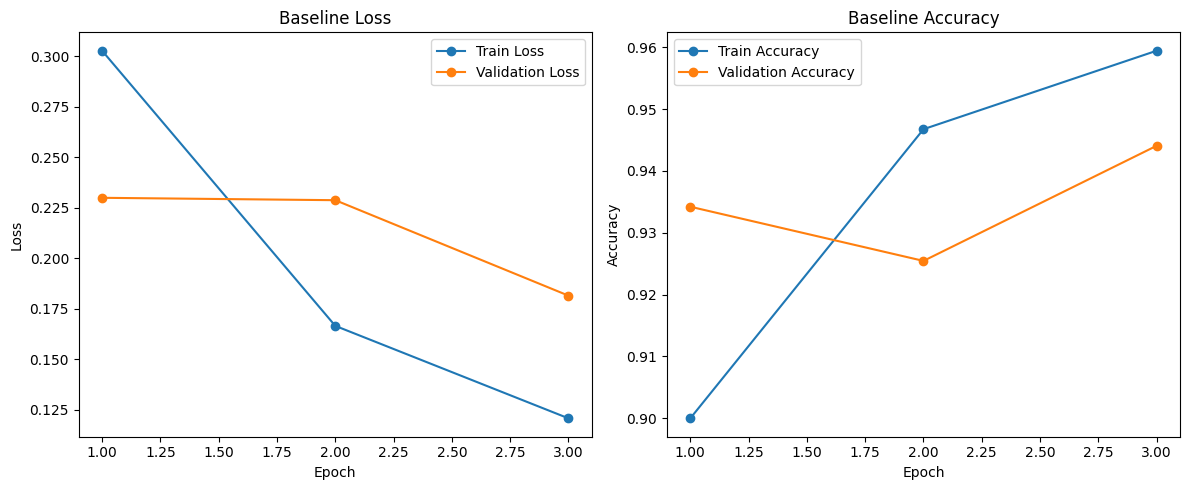

In [7]:

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], marker="o",
         label="Train Loss")
plt.plot(epochs_range, history["val_loss"], marker="o",
         label="Validation Loss")
plt.title("Baseline Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_accuracy"], marker="o",
         label="Train Accuracy")
plt.plot(epochs_range, history["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.title("Baseline Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_training_curves.png",
            dpi=300)
plt.show()


In [8]:
MODEL_PATH = PROJECT_DIR / "models" / "resnet18_baseline_best.pth"

print("Model exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    print("Model size (MB):",
          round(MODEL_PATH.stat().st_size / (1024 * 1024), 2))

Model exists: True
Model size (MB): 42.72
